<a href="https://colab.research.google.com/github/uasif2u-design/house-price-prediction-using-machine-learning/blob/main/indian_house_price.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import linear_model

In [ ]:
import pandas as pd
df = pd.read_csv("indian_house_prices (1).csv")
print(df.columns)

Index(['property_id', 'city', 'locality', 'property_type', 'bhk', 'bathrooms',
       'area_sqft', 'age_of_property_yrs', 'floor_number', 'total_floors',
       'furnishing_status', 'parking_spaces', 'has_lift', 'has_gym',
       'has_pool', 'has_security', 'has_power_backup', 'has_garden',
       'amenity_score', 'distance_metro_km', 'distance_school_km',
       'distance_hospital_km', 'buyer_annual_income_inr',
       'loan_eligibility_inr', 'transaction_type', 'sale_year', 'price_lakhs'],
      dtype='object')


In [ ]:
df = pd.read_csv("indian_house_prices (1).csv")
df = df.dropna()

# Encode categorical
df = pd.get_dummies(df, drop_first=True)

X = df.drop("price_lakhs", axis=1)
y = df["price_lakhs"]

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_csv("indian_house_prices (1).csv")

# 🔹 Step 3: Basic Info
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData Types:\n", df.dtypes)

Shape: (1200, 27)

Columns: ['property_id', 'city', 'locality', 'property_type', 'bhk', 'bathrooms', 'area_sqft', 'age_of_property_yrs', 'floor_number', 'total_floors', 'furnishing_status', 'parking_spaces', 'has_lift', 'has_gym', 'has_pool', 'has_security', 'has_power_backup', 'has_garden', 'amenity_score', 'distance_metro_km', 'distance_school_km', 'distance_hospital_km', 'buyer_annual_income_inr', 'loan_eligibility_inr', 'transaction_type', 'sale_year', 'price_lakhs']

Data Types:
 property_id                 object
city                        object
locality                    object
property_type               object
bhk                          int64
bathrooms                    int64
area_sqft                    int64
age_of_property_yrs        float64
floor_number               float64
total_floors                 int64
furnishing_status           object
parking_spaces             float64
has_lift                     int64
has_gym                    float64
has_pool            

In [ ]:
# 🔹 Step 4: Handle Missing Values (Basic)
df = df.dropna()  # simple approach for beginners

In [ ]:
# 🔹 Step 5: Summary Statistics
print("\nSummary Statistics:\n", df.describe())



Summary Statistics:
               bhk   bathrooms     area_sqft  age_of_property_yrs  \
count  862.000000  862.000000    862.000000           862.000000   
mean     2.546404    2.655452   1275.230858            17.232019   
std      0.986343    1.104667   2201.948039             9.897125   
min      1.000000    1.000000    250.000000             0.000000   
25%      2.000000    2.000000    815.500000             8.250000   
50%      2.000000    3.000000   1088.000000            18.000000   
75%      3.000000    3.000000   1424.250000            26.000000   
max      5.000000    6.000000  48461.000000            34.000000   

       floor_number  total_floors  parking_spaces    has_lift     has_gym  \
count    862.000000    862.000000      862.000000  862.000000  862.000000   
mean      14.295824     19.306265        1.183295    0.914153    0.277262   
std        8.518039      8.978044        0.704259    0.280300    0.447907   
min        0.000000      1.000000        0.000000    0.00

In [ ]:
# 🔹 Step 6: Value Counts (Categorical)
print("\nCity Value Counts:\n", df['city'].value_counts())
print("\nLocality Value Counts:\n", df['locality'].value_counts())


City Value Counts:
 city
Delhi        200
Mumbai       162
Bangalore    140
Hyderabad    111
Chennai       85
Kolkata       84
Pune          80
Name: count, dtype: int64

Locality Value Counts:
 locality
Vasant Kunj        40
Lajpat Nagar       33
Rohini             32
HSR Layout         29
Kondapur           29
Marathahalli       28
Karol Bagh         27
Pitampura          26
Andheri            26
Thane              25
Navi Mumbai        25
Gachibowli         25
Whitefield         25
Jubilee Hills      24
Borivali           24
Salt Lake          23
Porur              22
Electronic City    22
Dwarka             21
Saket              21
Malad              21
Bandra             21
Powai              20
Koramangala        19
Anna Nagar         18
Indiranagar        17
Banjara Hills      17
Hitech City        16
Hadapsar           16
Viman Nagar        15
Ballygunge         15
Hinjewadi          14
New Town           14
Adyar              13
Tollygunge         13
Baner              12
Kot

In [ ]:
import pickle
pickle.dump(X.columns.tolist(), open("columns.pkl","wb"))

In [ ]:
# 🔹 Step 7: Correlation (only numeric)
corr = df.corr(numeric_only=True)


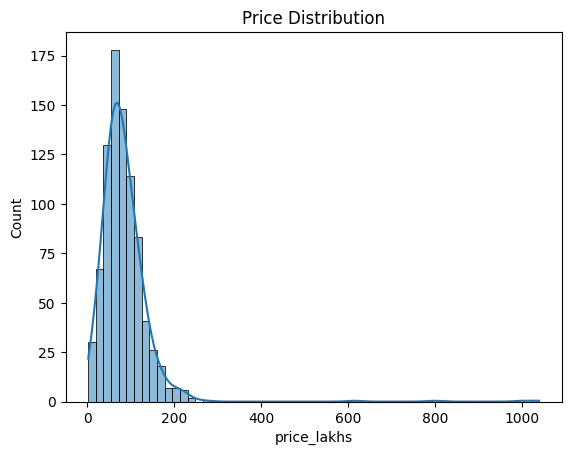

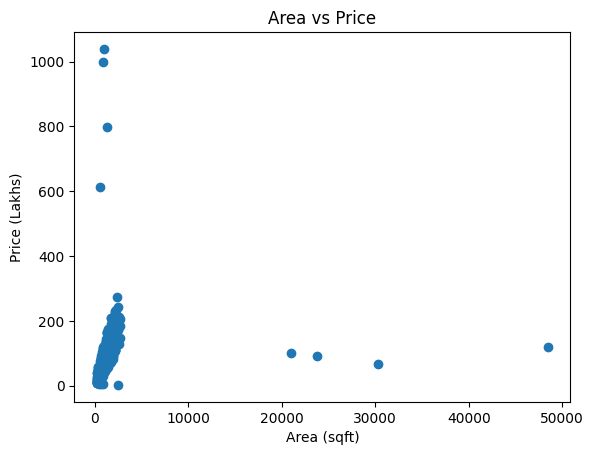

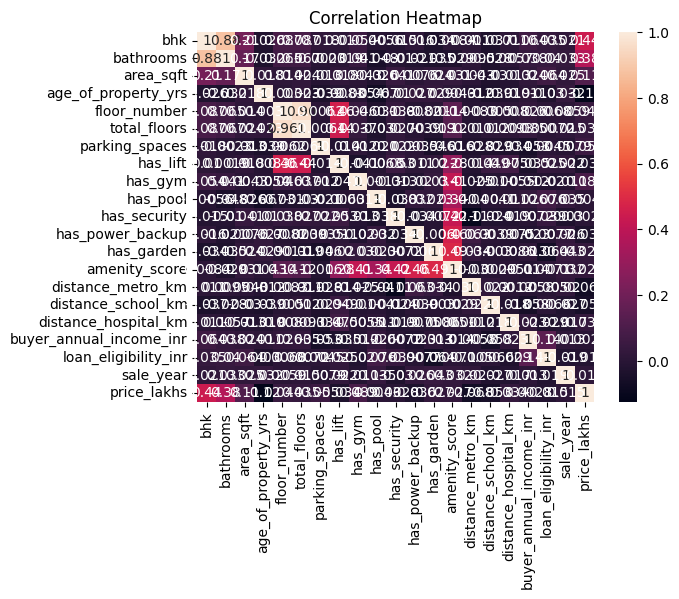

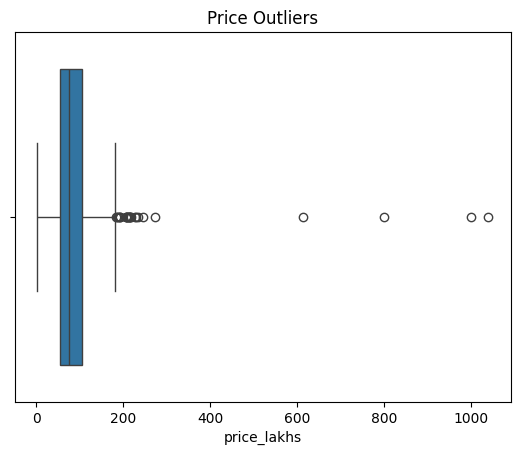

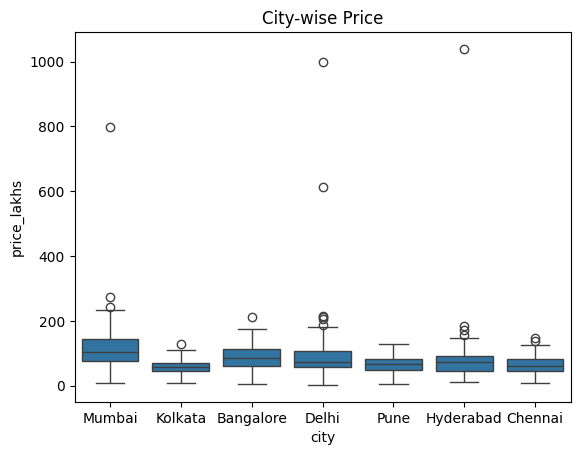

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 🔹 Step 8: Visualizations

# 1. Price Distribution
plt.figure()
sns.histplot(df['price_lakhs'], kde=True)
plt.title("Price Distribution")
plt.show()

# 2. Area vs Price
plt.figure()
plt.scatter(df['area_sqft'], df['price_lakhs'])
plt.xlabel("Area (sqft)")
plt.ylabel("Price (Lakhs)")
plt.title("Area vs Price")
plt.show()

# 3. Correlation Heatmap
plt.figure()
sns.heatmap(corr, annot=True)
plt.title("Correlation Heatmap")
plt.show()

# 4. Boxplot for Outliers
plt.figure()
sns.boxplot(x=df['price_lakhs'])
plt.title("Price Outliers")
plt.show()

# 5. City-wise Price Comparison
plt.figure()
sns.boxplot(x='city', y='price_lakhs', data=df)
plt.title("City-wise Price")
plt.show()

In [ ]:
import pandas as pd
import pickle

# Load dataset
df = pd.read_csv("indian_house_prices (1).csv")

# Basic preprocessing
df = df.dropna()
df = pd.get_dummies(df, drop_first=True)

X = df.drop("price_lakhs", axis=1)
y = df["price_lakhs"]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor()
model.fit(X_train, y_train)

# Save model + columns
pickle.dump(model, open("model.pkl", "wb"))
pickle.dump(X.columns.tolist(), open("columns.pkl", "wb"))

print("Model and columns saved")

Model and columns saved


In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import pickle

model = pickle.load(open("model.pkl", "rb"))
columns = pickle.load(open("columns.pkl", "rb"))

st.title("🏠 House Price Prediction (India)")

# Inputs
area = st.number_input("Area (sqft)", 300, 10000, 1000)
bedrooms = st.slider("Bedrooms", 1, 5, 2)
bathrooms = st.slider("Bathrooms", 1, 4, 2)
age = st.slider("Age of House", 0, 30, 5)
income = st.number_input("Annual Income (INR)", 100000, 5000000, 500000)

city = st.selectbox("City", ["Delhi", "Mumbai", "Bangalore"])
location = st.selectbox("Location", ["urban", "suburban", "rural"])

# Prepare input
input_dict = {
    'area_sqft': area,
    'bedrooms': bedrooms,
    'bathrooms': bathrooms,
    'age': age,
    'annual_income': income,
    'city_Delhi': 0,
    'city_Mumbai': 0,
    'city_Bangalore': 0,
    'location_urban': 0,
    'location_suburban': 0,
    'location_rural': 0
}

input_dict[f'city_{city}'] = 1
input_dict[f'location_{location}'] = 1

input_df = pd.DataFrame([input_dict])

# Align columns
for col in columns:
    if col not in input_df:
        input_df[col] = 0

input_df = input_df[columns]

# Predict
if st.button("Predict Price"):
    pred = model.predict(input_df)[0]
    st.success(f"Estimated Price: ₹ {int(pred):,}")

Writing app.py


In [ ]:
import gradio as gr
import pandas as pd
import pickle

model = pickle.load(open("model.pkl","rb"))
columns = pickle.load(open("columns.pkl","rb"))

# Define base inputs manually (important ones only)
def predict(area, bedrooms, bathrooms, age, income, gym, pool, parking, city, location):

    input_dict = {col: 0 for col in columns}

    # numeric
    input_dict['area_sqft'] = area
    input_dict['bedrooms'] = bedrooms
    input_dict['bathrooms'] = bathrooms
    input_dict['age'] = age
    input_dict['annual_income'] = income

    # new columns (your problem FIXED here)
    input_dict['gym'] = gym
    input_dict['swimming_pool'] = pool
    input_dict['parking'] = parking

    # categorical encoding
    if f'city_{city}' in input_dict:
        input_dict[f'city_{city}'] = 1

    if f'location_{location}' in input_dict:
        input_dict[f'location_{location}'] = 1

    df = pd.DataFrame([input_dict])
    df = df[columns]

    pred = model.predict(df)[0]
    return f"Estimated Price: ₹ {int(pred):,}"


demo = gr.Interface(
    fn=predict,
    inputs=[
        gr.Number(label="Area (sqft)"),
        gr.Slider(1,5,step=1,label="Bedrooms"),
        gr.Slider(1,4,step=1,label="Bathrooms"),
        gr.Slider(0,30,step=1,label="Age"),
        gr.Number(label="Annual Income"),

        # ✅ FIXED FEATURES
        gr.Radio([0,1], label="Gym"),
        gr.Radio([0,1], label="Swimming Pool"),
        gr.Radio([0,1], label="Parking"),

        gr.Dropdown(["Delhi","Mumbai","Bangalore"], label="City"),
        gr.Dropdown(["urban","suburban","rural"], label="Location"),
    ],
    outputs="text",
    title="House Price Prediction (Fixed Columns)"
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1a9d192cf24dfdcc61.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
